# 3d (EBAIS variant) — Baseline Accessibility Analysis: Primary Care, Costa Rica

## Purpose
Compute nearest-EBAIS travel times for the Costa Rican population and produce access-time figures.

Sinks are the **949 EBAIS** (*Equipos Básicos de Atención Integral en Salud*, the CCSS primary-care units) of `input_files/salud/ebais_cr.shp`. Hospitals are *not* included — they are the sinks of the sibling notebook `3d_Baseline_Accesibility_Analysis-hospital_CR.ipynb` (27 points). Read the two together for the two tiers of the public health system: this notebook answers "how far is the nearest primary-care unit", the hospital notebook "how far is the nearest hospital".

The OSM-based run (`amenity=hospital` / `amenity=clinic`, 1 242 facilities, in `3d_Baseline_Accesibility_Analysis-hospital_OSM_CR.ipynb`) mixes both tiers and is the closest OSM analogue to this one, though its tagging is uneven.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | Directed, AADT-attributed main road network produced in 1b (EPSG:8908, `fft` in hours) |
| `input_files/cri_pd_2020_1km_UNadj_ASCII_XYZ.csv` | WorldPop 2020 UN-adjusted 1 km population **density** grid (WGS84, people per km²) |
| `input_files/salud/ebais_cr.shp` | EBAIS register — 949 geocoded points (WGS84), with `provincia`/`canton`/`distrito`, a Google `place_id` and the geocoding `metodo` per unit |

## Outputs
All outputs go to EBAIS-specific directories. The filenames and GDB layer names inside them are fixed by `utils.accessibility_functions` (`hospital_access.png`, `hospitals.parquet`, …) because the shared helpers only accept the facility types `firefighters` / `hospitals` / `police`; this notebook passes `"hospitals"` and keeps the files apart by directory, so no shared source had to change. **The `hospital*` filenames under `ebais/` hold EBAIS results.**

| File | Description |
|------|-------------|
| `figures/ebais/baseline_accessibility_hospitals.png` | Cumulative accessibility curve (population share vs. travel time) |
| `figures/ebais/hospital_access.png` | Map of nearest-EBAIS access times per 1 km population cell |
| `figures/ebais/hospital_access_chart.png` | Population distribution chart by access-time band |
| `intermediate_results/parquet/local_accessibility/ebais/hospital_accessibility_results.parquet` | Grid-cell access-time results (EPSG:8908) |
| `intermediate_results/parquet/local_accessibility/ebais/hospitals.parquet` | EBAIS sink points (EPSG:8908) |
| `intermediate_results/database/local_accessibility/local_accessibility_ebais.gdb` | GDB layers: `hospital_accessibility_results`, `hospitals` |

## Key Processing Steps
1. **Load EBAIS** — read the register shapefile and drop repeated `place_id`s
2. **Load network** — read the directed main network from 1b and build an igraph graph (`fft` edge weights)
3. **Population grid** — convert WorldPop density to people per cell, snap each cell to the nearest network node
4. **Snap facilities** — nearest network node per EBAIS in the metric CRS
5. **Nearest-facility computation** — shortest-path travel time to the closest EBAIS for every cell
6. **Save results** — write Parquet and ArcGIS File Geodatabase layers in EPSG:8908
7. **Plot curve, map and chart** — cumulative access curve, spatial access-time map, population by access band

## Caveats
- Travel times are network times on the **main network only** (1b scope): population cells and EBAIS snap to the nearest network node, so the first/last mile on local streets is not counted. With 949 densely spread sinks most cells snap to a node very close to their nearest EBAIS, which compresses the short end of the distribution towards zero.
- Coordinates come from Google Places geocoding; `metodo` records how each was resolved — `nombre_explicito` (name matched directly) or `proximidad` (matched by proximity, the weaker case, and the bulk of the file). A point may sit near rather than exactly on the unit.
- `provincia`/`canton`/`distrito` are the administrative unit the EBAIS was *searched* under, not necessarily the one the geocoded point falls in — do not use them for administrative aggregation without a spatial join.
- EBAIS provide primary care only; reaching one is not equivalent to reaching emergency or inpatient care.
- Where several EBAIS snap to the same network node the travel times are unaffected, but `closest_sink_osm_id` names only one of them — treat it as "an EBAIS at the nearest node", not necessarily the specific unit a person would attend.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path.cwd().parent  # notebook lives in /notebooks
sys.path.append(str(BASE_DIR))

from utils.accessibility_functions import (
    create_graph_for_spatial_matching,
    map_settlements_to_nodes_in_road_network,
    nearest_network_nodes,
    get_distance_to_nearest_facility,
    save_accessibility_results,
    plot_access_curve,
    plot_access_time_map,
)

In [2]:
# All paths are hard-coded here (no NetworkConfig) so they can be swapped one by one.
data_path = BASE_DIR / "input_files"
intermediate_path = BASE_DIR / "intermediate_results"

# Inputs
path_road_network = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"  # from 1b
path_population = data_path / "cri_pd_2020_1km_UNadj_ASCII_XYZ.csv"  # WorldPop 1 km density grid
path_ebais = data_path / "salud" / "ebais_cr.shp"  # EBAIS primary-care register (WGS84 points)

# Outputs — this EBAIS variant writes to its own "ebais" figure folder, parquet
# folder and geodatabase. The filenames and GDB layer names inside them are fixed
# by utils.accessibility_functions (hospital_access.png, hospitals.parquet, ...),
# which only knows the facility types firefighters/hospitals/police, so separate
# directories are what keeps this run from overwriting the hospital run in
# 3d_Baseline_Accesibility_Analysis-hospital_CR.ipynb (canonical paths) and the
# OSM run in 3d_Baseline_Accesibility_Analysis-hospital_OSM_CR.ipynb (osm paths).
figure_dir = BASE_DIR / "figures" / "ebais"
parquet_dir = intermediate_path / "parquet" / "local_accessibility" / "ebais"
gdb_path = intermediate_path / "database" / "local_accessibility" / "local_accessibility_ebais.gdb"
output_crs = "EPSG:8908"  # CR-SIRGAS / CRTM05 (metres) — same working CRS as notebooks 1b/2

for p in (path_road_network, path_population, path_ebais):
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "If this path lives on OneDrive, make sure the folder is downloaded locally "
            "('Always keep on this device') — cloud placeholders cannot be opened."
        )

In [3]:
import geopandas as gpd
import pandas as pd

# EBAIS (Equipos Básicos de Atención Integral en Salud) — the CCSS primary-care
# units, from the official register geocoded with Google Places (one `place_id`
# per unit) and delivered as a WGS84 point shapefile. Hospitals are NOT part of
# this run; they are the sinks of 3d_..._hospital_CR.
ebais = gpd.read_file(path_ebais)
assert ebais.crs is not None and ebais.crs.to_epsg() == 4326, (
    f"Expected EPSG:4326, found {ebais.crs}"
)

# Drop repeats of the same Google place (the same unit listed twice under
# different names or districts). Unlike the hospital register this file has no
# `estado` column — every row is a resolved geocode — but `metodo` records how:
# `nombre_explicito` (name matched directly) or `proximidad` (matched by
# proximity, the weaker case). Both are kept; the split is printed below.
n_raw = len(ebais)
ebais = ebais.drop_duplicates(subset="place_id").reset_index(drop=True)

# `place_id` is the stable per-unit id used as the sink identifier below.
# `provincia`/`canton`/`distrito` are the unit the EBAIS was searched under, not
# necessarily where the point lands — carried through for reference only.
ebais["name"] = ebais["nombre_goo"]
ebais = ebais[
    ["place_id", "name", "provincia", "canton", "distrito", "direccion", "metodo", "geometry"]
]

# Longitude/Latitude columns to match the sink layout used by the Serbia inputs
ebais["Longitude"] = ebais.geometry.x
ebais["Latitude"] = ebais.geometry.y

print(f"{len(ebais)} EBAIS kept out of {n_raw} register records")
print(ebais["metodo"].value_counts().to_string())
ebais.head()

949 EBAIS kept out of 949 register records
metodo
proximidad          859
nombre_explicito     90


,place_id,name,provincia,canton,distrito,direccion,metodo,geometry,Longitude,Latitude
0,ChIJkX9TWB_5oI8RvifhWpZZS7k,Ebais Alajuela Central CCSS,Alajuela,Alajuela,Alajuela,"2Q8Q+CCP, C. 3 Arroyo, Provincia de Alajuela, ...",proximidad,POINT (-84.21142 10.01609),-84.211423,10.016093
1,ChIJ48k3_r_5oI8RiA3V5OOhx_A,Ebais El Invu 3,Alajuela,Alajuela,Alajuela,"2Q5V+474, Provincia de Alajuela, Alajuela, Inv...",proximidad,POINT (-84.20681 10.00777),-84.206808,10.007768
2,ChIJq6pa-hH5oI8Ry1SsZyryWjA,Ebais de San Rafael,Alajuela,Alajuela,Alajuela,"XQFP+MX5, Provincia de Alajuela, San Rafael, C...",proximidad,POINT (-84.21252 9.97414),-84.212523,9.974144
3,ChIJUfMsbGf5oI8RRroXL92ykgo,Ebais de Río Segundo,Alajuela,Alajuela,Alajuela,"Provincia de Alajuela, Río Segundo, Costa Rica",proximidad,POINT (-84.18634 10.00338),-84.186337,10.003383
4,ChIJ0TMQXSr6oI8RF6uFVacaMSc,EBAIS Tipo 2 La Ribera,Alajuela,Alajuela,Alajuela,"XRR8+HF2, C. Arbolito, Heredia, Belén, Urb. Za...",proximidad,POINT (-84.18386 9.9914),-84.183855,9.991399


In [4]:
# Calibri is not installed on every machine (e.g. macOS); fall back quietly.
import matplotlib.font_manager as fm

if any(f.name == "Calibri" for f in fm.fontManager.ttflist):
    plt.rcParams["font.family"] = "Calibri"

In [5]:
# Build graph + nodes, snap population grid, snap facilities, compute nearest access time
base_network = gpd.read_file(path_road_network, layer="main_network_directed")
assert base_network.crs is not None and base_network.crs.to_epsg() == 8908, (
    f"Expected EPSG:8908, found {base_network.crs}"
)
missing = {"from_id", "to_id", "id", "fft"} - set(base_network.columns)
assert not missing, f"Network is missing required columns: {missing}"

nodes, graph = create_graph_for_spatial_matching(base_network)

# WorldPop 1 km grid: Z is population DENSITY (people per km²), so convert to
# people per cell with the latitude-dependent 30-arc-second cell area.
df_worldpop = pd.read_csv(path_population).rename(columns={"Z": "density"})
df_worldpop = df_worldpop[df_worldpop["density"] > 0].reset_index(drop=True)
cell_deg = 1 / 120  # 30 arc-seconds
cell_area_km2 = (111.320 * np.cos(np.radians(df_worldpop["Y"])) * cell_deg) * (
    110.574 * cell_deg
)
df_worldpop["population"] = df_worldpop["density"] * cell_area_km2
df_worldpop = gpd.GeoDataFrame(
    df_worldpop,
    geometry=gpd.points_from_xy(df_worldpop["X"], df_worldpop["Y"]),
    crs="EPSG:4326",
).to_crs(base_network.crs)
print(
    f"Population cells: {len(df_worldpop):,} | "
    f"total population: {df_worldpop['population'].sum():,.0f}"
)

df_worldpop = map_settlements_to_nodes_in_road_network(df_worldpop, nodes)

# Snap the register EBAIS (EPSG:4326) to the network in the metric CRS. Many of
# the 949 units share a network node, so the number of distinct sink vertices is
# well below the number of units — that is expected on a main-network-only graph.
sink_ebais = ebais.to_crs(base_network.crs)
nearest_network_nodes(sink_ebais, nodes)
print(
    f"{sink_ebais['vertex_id'].nunique()} distinct network nodes for "
    f"{len(sink_ebais)} EBAIS"
)

# Nearest EBAIS for each population cell (slow step). The shared helper names its
# output columns closest_sink_osm_id/... regardless of the id column used — here
# that column holds the register's Google `place_id`.
df_worldpop = get_distance_to_nearest_facility(
    df_worldpop, sink_ebais, graph, id_col="place_id"
)

# The closest_sink_* columns come back as object dtype; make them file-format safe
df_worldpop["closest_sink_total_fft"] = pd.to_numeric(
    df_worldpop["closest_sink_total_fft"], errors="coerce"
)
df_worldpop["closest_sink_vertex_id"] = pd.to_numeric(
    df_worldpop["closest_sink_vertex_id"], errors="coerce"
)
df_worldpop["closest_sink_osm_id"] = df_worldpop["closest_sink_osm_id"].astype(str)

100%|██████████| 9764/9764 [00:00<00:00, 24218.61it/s]


Population cells: 62,053 | total population: 5,137,882


100%|██████████| 949/949 [00:00<00:00, 5222.75it/s]


767 distinct network nodes for 949 EBAIS


WorldPop: 2,438 occupied hexagons, 5,137,882 people (sum of cells = 5,137,882)
Localities: 493 points, 5,167,278 people (INEC projection)
pop_bin
(1.9380000000000002, 114.362]    488
(114.362, 265.251]               487
(265.251, 530.395]               488
(530.395, 1405.193]              487
(1405.193, 197760.69]            488


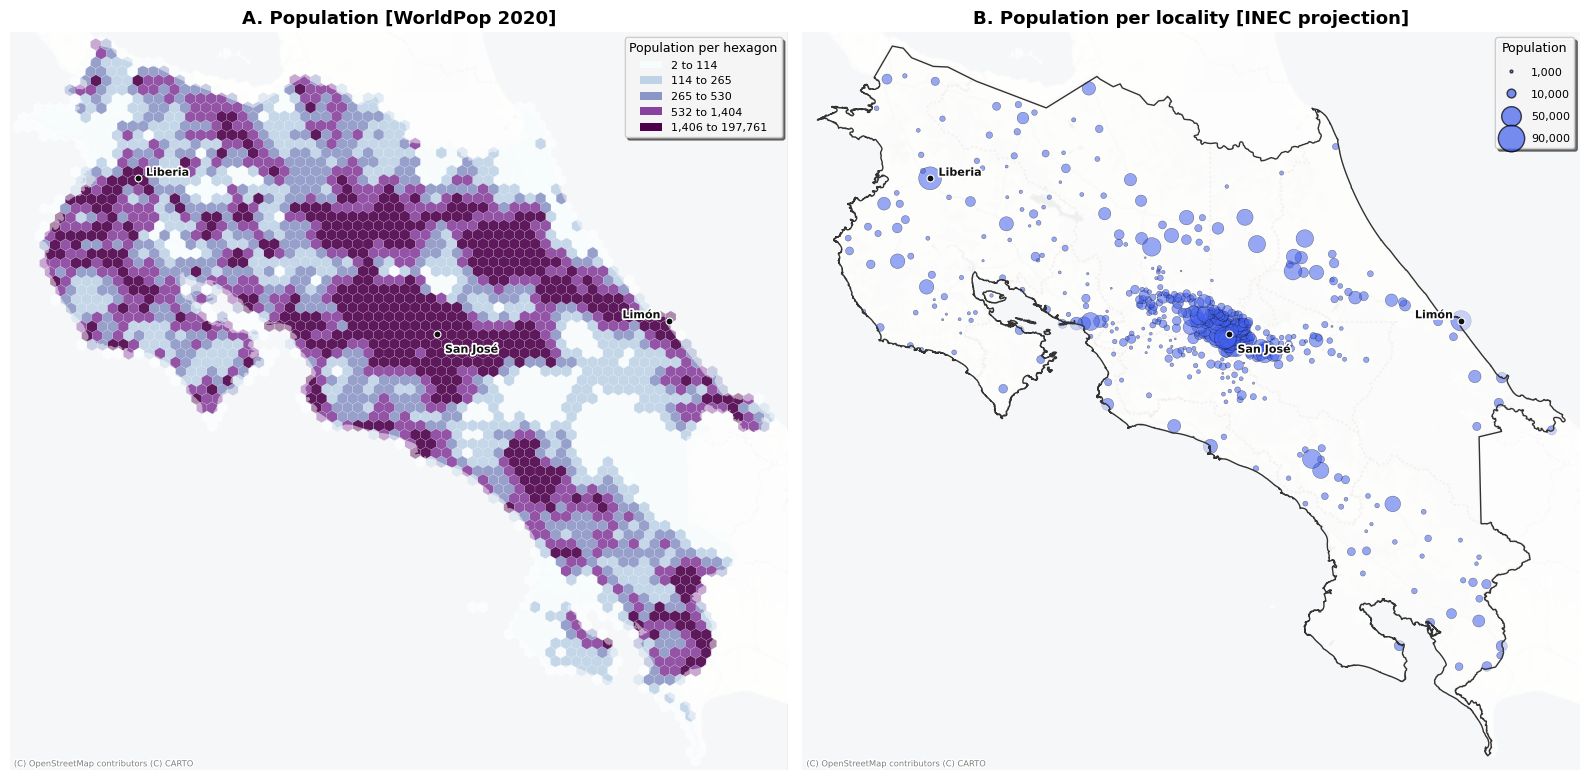

In [10]:
# Population maps in the shared CR map style.
# Assumptions: the Serbia hexagon map is not in this repository, so the hex look is
# my own - pointy-top hexagons, circumradius HEX_RADIUS_M, WorldPop population summed
# per hexagon, coloured in equal-count quintiles of the occupied hexagons.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import Polygon

from src.map_style_cr import add_cr_legend, style_cr_map

HEX_RADIUS_M = 3_000          # ~6 km flat-to-flat; ~30 WorldPop 1 km cells per hexagon
BINS_N = 5
LOCALITIES_SHP = data_path / "CENTROS_POBLACION" / "centros_poblados_localidades.shp"


def build_hex_population(points, radius):
    """Sum points['population'] into a pointy-top hexagonal grid (metric CRS)."""
    x, y = points.geometry.x.to_numpy(), points.geometry.y.to_numpy()
    # Pixel -> fractional axial coordinates, then cube-round to the nearest hexagon
    q = (np.sqrt(3) / 3 * x - y / 3) / radius
    r = (2 / 3 * y) / radius
    s = -q - r
    rq, rr, rs = np.round(q), np.round(r), np.round(s)
    dq, dr, ds = np.abs(rq - q), np.abs(rr - r), np.abs(rs - s)
    fix_q = (dq > dr) & (dq > ds)
    fix_r = ~fix_q & (dr > ds)
    rq = np.where(fix_q, -rr - rs, rq)
    rr = np.where(fix_r, -rq - rs, rr)

    hexes = (
        pd.DataFrame({"q": rq.astype(int), "r": rr.astype(int),
                      "population": points["population"].to_numpy()})
        .groupby(["q", "r"], as_index=False)["population"].sum()
    )
    cx = radius * np.sqrt(3) * (hexes["q"] + hexes["r"] / 2)
    cy = radius * 1.5 * hexes["r"]
    angles = np.radians(30 + 60 * np.arange(6))
    hexes["geometry"] = [
        Polygon(zip(x0 + radius * np.cos(angles), y0 + radius * np.sin(angles)))
        for x0, y0 in zip(cx, cy)
    ]
    return gpd.GeoDataFrame(hexes, geometry="geometry", crs=points.crs)


hex_pop = build_hex_population(df_worldpop, HEX_RADIUS_M)
hex_pop["pop_bin"] = pd.qcut(hex_pop["population"], q=BINS_N, duplicates="drop")
hex_pop_web = hex_pop.to_crs(3857)

localities = gpd.read_file(LOCALITIES_SHP).to_crs(8908)
localities = localities.loc[localities["INEC_PROY"] > 0].copy()
localities_web = localities.to_crs(3857)

print(f"WorldPop: {len(hex_pop):,} occupied hexagons, "
      f"{hex_pop['population'].sum():,.0f} people (sum of cells = {df_worldpop['population'].sum():,.0f})")
print(f"Localities: {len(localities):,} points, {localities['INEC_PROY'].sum():,.0f} people (INEC projection)")
print(hex_pop["pop_bin"].value_counts(sort=False).to_string())
fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")

# ---- A. WorldPop hexagons --------------------------------------------------
ax = axes[0]
categories = hex_pop_web["pop_bin"].cat.categories
colors = plt.get_cmap("BuPu", len(categories))
handles = []
for i, category in enumerate(categories):
    subset = hex_pop_web.loc[hex_pop_web["pop_bin"] == category]
    subset.plot(ax=ax, color=colors(i), linewidth=0.1, edgecolor="white", alpha=0.9, zorder=2 + i)
    # Label with the values actually in the class, not the qcut edges
    handles.append(Patch(facecolor=colors(i), edgecolor="none",
                         label=f"{subset['population'].min():,.0f} to {subset['population'].max():,.0f}"))
ax.set_title("A. Population [WorldPop 2020]", fontsize=13, fontweight="bold")
style_cr_map(ax, 3857, basemap=True, boundary=False, legend_handles=handles,
             legend_title=f"Population per hexagon",
             legend_kw=dict(fontsize=8, title_fontsize=9), city_fontsize=8)

# ---- B. Locality points, area proportional to population --------------------
ax = axes[1]
SIZE_SCALE = 0.004   # marker area (pt^2) per person; the biggest locality is ~360 pt^2
localities_web.plot(
    ax=ax, color="#4361ee", markersize=localities_web["INEC_PROY"] * SIZE_SCALE,
    alpha=0.55, edgecolor="black", linewidth=0.3, zorder=3,
)
ax.set_title("B. Population per locality [INEC projection]", fontsize=13, fontweight="bold")
size_handles = [
    Line2D([0], [0], marker="o", linestyle="None", markerfacecolor="#4361ee",
           markeredgecolor="black", alpha=0.7,
           markersize=np.sqrt(v * SIZE_SCALE), label=f"{v:,}")
    for v in (1_000, 10_000, 50_000, 90_000)
]
style_cr_map(ax, 3857, basemap=True, legend_handles=size_handles,
             legend_title="Population", legend_kw=dict(fontsize=8, title_fontsize=9,
                                                      labelspacing=1.1), city_fontsize=8)

plt.tight_layout()
figure_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figure_dir / "population_hexagons_and_localities.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# Save results (Parquet + ArcGIS File Geodatabase, in the chosen output CRS).
# "hospitals" is the facility_type the shared helper understands; the EBAIS-specific
# parquet_dir/gdb_path set above are what separate these files from the hospital run,
# so the hospital*/travel_time_hosp names below hold EBAIS numbers.
save_accessibility_results(
    df_worldpop, sink_ebais, "hospitals", parquet_dir, gdb_path, output_crs
)

Saved hospital_accessibility_results -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/parquet/local_accessibility/ebais/hospital_accessibility_results.parquet
Saved hospital_accessibility_results -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/database/local_accessibility/local_accessibility_ebais.gdb (layer 'hospital_accessibility_results')
Saved hospitals -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/parquet/local_accessibility/ebais/hospitals.parquet
Saved hospitals -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/database/local_accessibility/local_accessibility_ebais.gdb (layer 'hospitals')


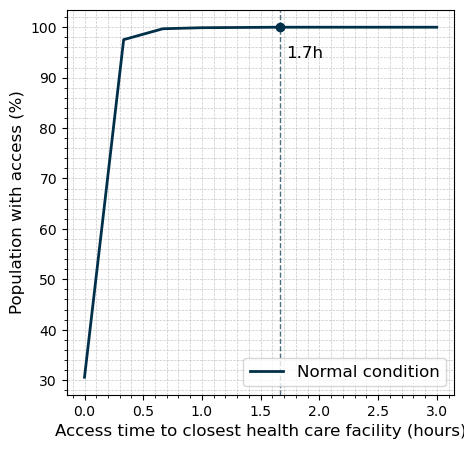

In [7]:
# Cumulative access curve. The shared plotter's x-label ("Access time to closest
# health care facility") already fits EBAIS; only the file lands under figures/ebais/.
plot_access_curve(df_worldpop, "hospitals", figure_dir)

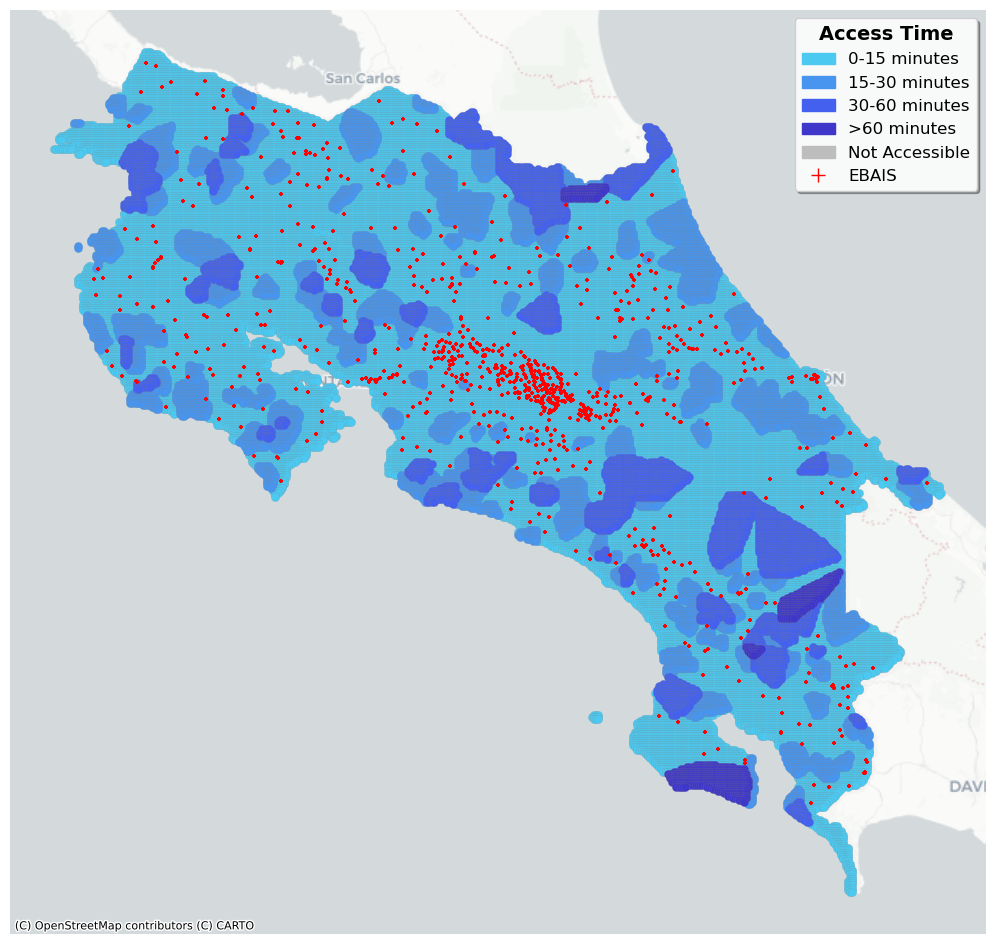

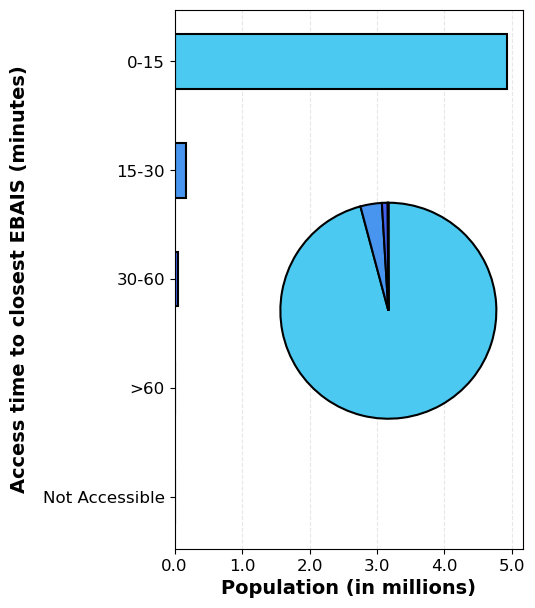

In [8]:
def plot_accessibility_chart_cr(df_worldpop_plot, figure_dir, show=True):
    """
    Costa Rica variant of utils' plot_accessibility_chart.

    The generic chart reindexes on hour-based categories ("60-90", ">120", ...)
    that plot_access_time_map does not produce, silently dropping the ">60" and
    "Not Accessible" population. This variant uses the exact categories and
    colours of the map so the two figures agree.
    """
    category_order = ["0-15", "15-30", "30-60", ">60", "Not Accessible"]
    category_colors = ["#4cc9f0", "#4895ef", "#4361ee", "#3f37c9", "#bdbdbd"]
    color_dict = dict(zip(category_order, category_colors))

    pop_by_category = (
        df_worldpop_plot.groupby("category")["population"].sum() / 1e6
    ).reindex(category_order, fill_value=0)
    pop_by_category_reversed = pop_by_category[::-1]

    fig, ax = plt.subplots(figsize=(4.5, 7))
    ax.barh(
        range(len(pop_by_category_reversed)),
        pop_by_category_reversed.values,
        height=0.5,
        color=[color_dict[cat] for cat in pop_by_category_reversed.index],
        edgecolor="black",
        linewidth=1.5,
    )
    ax.set_ylabel(
        "Access time to closest EBAIS (minutes)",
        fontsize=14,
        fontweight="bold",
        labelpad=10,
    )
    ax.set_xlabel("Population (in millions)", fontsize=14, fontweight="bold")
    ax.set_yticks(range(len(pop_by_category_reversed)))
    ax.set_yticklabels(pop_by_category_reversed.index, fontsize=12)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.1f}"))
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(axis="x", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

    # Inset pie chart, same order and colours as the bars
    ax_inset = fig.add_axes([0.3, 0.15, 0.6, 0.6])
    ax_inset.pie(
        pop_by_category.values,
        colors=[color_dict[cat] for cat in pop_by_category.index],
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "black", "linewidth": 1.5},
    )

    figure_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(figure_dir / "hospital_access_chart.png", dpi=200, bbox_inches="tight")
    if show:
        plt.show()


# Access-time map. The shared plotter hard-codes the sink legend entry as
# "hospitals" and draws the sinks at markersize=100, which is unreadable with 949
# EBAIS, so the figure is drawn with show=False, the legend entry and marker size
# are corrected on the still-current figure, and it is re-saved over the file the
# plotter just wrote.
df_worldpop_plot = plot_access_time_map(
    df_worldpop, sink_ebais, "hospitals", figure_dir, show=False
)

ax_map = plt.gca()
sink_artist = ax_map.collections[-1]  # the sink layer is plotted last
assert len(sink_artist.get_offsets()) == len(sink_ebais), (
    "Expected the last drawn collection to be the EBAIS sinks"
)
sink_artist.set_sizes([12])

legend_map = ax_map.get_legend()
for text in legend_map.get_texts():
    if text.get_text() == "hospitals":
        text.set_text("EBAIS")
for handle in legend_map.legend_handles:
    if getattr(handle, "get_marker", lambda: None)() == "+":
        handle.set_markersize(10)

plt.savefig(figure_dir / "hospital_access.png", dpi=200, bbox_inches="tight")
plt.show()

# Population distribution chart
plot_accessibility_chart_cr(df_worldpop_plot, figure_dir)